## 5. PCA 

In [10]:
# ===========================================
#  Imports & Load MNIST
# ===========================================
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_openml

# Replace 'your_username' with your actual email username
username = "kuluri.sarvani"
import hashlib

# Seed from username
username = "kuluri.sarvani"
seed = int(hashlib.sha256(username.encode()).hexdigest(), 16) % (2**32)
# Load MNIST dataset (28x28 images, flattened to 784 features)
mnist = fetch_openml("mnist_784", version=1, as_frame=False)
X = mnist.data.astype(np.float64)
y = mnist.target.astype(int)

print("Dataset shape:", X.shape)
print("Labels shape:", y.shape)


Dataset shape: (70000, 784)
Labels shape: (70000,)


## 5.1 Custom Implementation 

In [11]:
# ===========================================
#  PCA Class (Custom Implementation)
# ===========================================
class PCA_Custom:
    """
    Principal Component Analysis (PCA) implementation from scratch.
    """

    def __init__(self, n_components):
        """
        Initialize PCA class.

        Parameters:
        -----------
        n_components : int
            Number of principal components to reduce data to.
        """
        self.n_components = n_components
        self.components_ = None
        self.mean_ = None
        self.explained_variance_ = None

    def fit(self, X):
        """
        Compute principal components of the dataset.

        Parameters:
        -----------
        X : np.ndarray
            Input dataset of shape (n_samples, n_features)
        """
        # Center the data
        self.mean_ = np.mean(X, axis=0)
        X_centered = X - self.mean_

        # Compute covariance matrix
        cov_matrix = np.cov(X_centered, rowvar=False)

        # Eigen decomposition
        eigen_values, eigen_vectors = np.linalg.eigh(cov_matrix)

        # Sort eigenvectors by decreasing eigenvalues
        sorted_idx = np.argsort(eigen_values)[::-1]
        self.explained_variance_ = eigen_values[sorted_idx][:self.n_components]
        self.components_ = eigen_vectors[:, sorted_idx][:, :self.n_components]

    def transform(self, X):
        """
        Transform data to lower-dimensional space using principal components.

        Parameters:
        -----------
        X : np.ndarray
            Input dataset of shape (n_samples, n_features)

        Returns:
        --------
        X_transformed : np.ndarray
            Dataset projected onto principal components.
        """
        X_centered = X - self.mean_
        return np.dot(X_centered, self.components_)

    def checkPCA(self, X):
        """
        Check if PCA reduces dimensions correctly.

        Parameters:
        -----------
        X : np.ndarray
            Input dataset

        Returns:
        --------
        bool : True if transformed data has correct shape, False otherwise
        """
        X_transformed = self.transform(X)
        return X_transformed.shape[1] == self.n_components


In [12]:
# ===========================================
# 🔹 Fit PCA and Transform MNIST
# ===========================================
n_components = 50  # Example: reduce to 50 dimensions
pca = PCA_Custom(n_components=n_components)

# Fit PCA
pca.fit(X)

# Transform data
X_pca = pca.transform(X)

# Check PCA
print("PCA reduces dimensions correctly:", pca.checkPCA(X))
print("Original shape:", X.shape)
print("Transformed shape:", X_pca.shape)


PCA reduces dimensions correctly: True
Original shape: (70000, 784)
Transformed shape: (70000, 50)


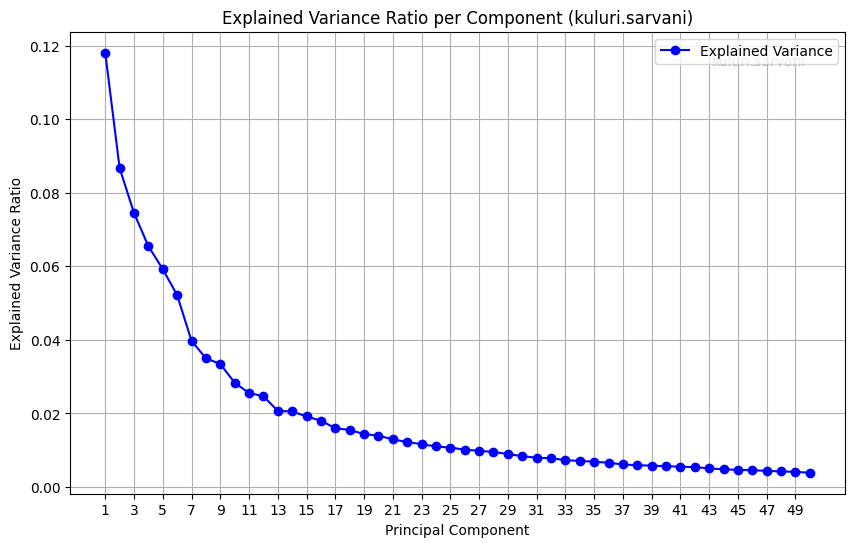

In [13]:
# ===========================================
#  Visualize Explained Variance
# ===========================================
explained_variance_ratio = pca.explained_variance_ / np.sum(pca.explained_variance_)

plt.figure(figsize=(10,6))
plt.plot(range(1, n_components+1), explained_variance_ratio, marker='o', linestyle='-', color='b', label="Explained Variance")
plt.title(f"Explained Variance Ratio per Component ({username})")
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.xticks(range(1, n_components+1, 2))
plt.legend()
plt.grid(True)
# ADD WATERMARK HERE
plt.text(0.95, 0.95, username,
        ha='right', va='top',
        transform=plt.gca().transAxes,
        fontsize=10, color='gray', alpha=0.7)
plt.show()


## 5.2 PCA on MNIST 

In [14]:
# ===========================================
#  Create Balanced MNIST Subset
# ===========================================
np.random.seed(seed)  # For reproducibility

# Collect 100 samples per digit (0-9)
subset_indices = []
for digit in range(10):
    digit_indices = np.where(y == digit)[0]
    selected_indices = np.random.choice(digit_indices, 100, replace=False)
    subset_indices.extend(selected_indices)

# Extract subset
X_subset = X[subset_indices]
y_subset = y[subset_indices]

print("Subset shape:", X_subset.shape)
print("Subset labels shape:", y_subset.shape)

# Verify balance
unique, counts = np.unique(y_subset, return_counts=True)
print("Label counts:", dict(zip(unique, counts)))


Subset shape: (1000, 784)
Subset labels shape: (1000,)
Label counts: {0: 100, 1: 100, 2: 100, 3: 100, 4: 100, 5: 100, 6: 100, 7: 100, 8: 100, 9: 100}


In [15]:
# ===========================================
# Confirm flattening (28x28 -> 784)
# ===========================================
print("Each image has shape:", X_subset[0].shape)  # Should be 784


Each image has shape: (784,)


In [16]:
# ===========================================
#  PCA Projection for Multiple Dimensions (FIXED)
# ===========================================
target_dimensions = [500, 300, 150, 30]
pca_results = {}

# First, compute total variance of the original data
total_variance = np.var(X_subset, axis=0).sum()

for n_dim in target_dimensions:
    pca_tmp = PCA_Custom(n_components=n_dim)
    pca_tmp.fit(X_subset)
    X_transformed = pca_tmp.transform(X_subset)
    
    # CORRECTED: Normalize by total variance, not just selected components
    pca_results[n_dim] = {
        "pca": pca_tmp,
        "X_transformed": X_transformed,
        "explained_variance_ratio": pca_tmp.explained_variance_ / total_variance  # This is the fix!
    }
    print(f"PCA done for {n_dim} components. Transformed shape: {X_transformed.shape}")

PCA done for 500 components. Transformed shape: (1000, 500)
PCA done for 300 components. Transformed shape: (1000, 300)
PCA done for 150 components. Transformed shape: (1000, 150)
PCA done for 30 components. Transformed shape: (1000, 30)


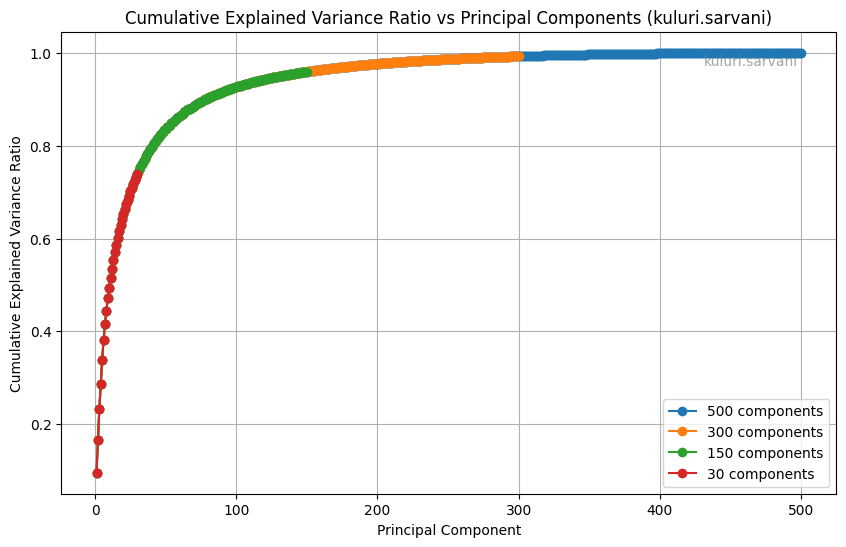

In [17]:
# ===========================================
#  Explained Variance Plot (CUMULATIVE)
# ===========================================
plt.figure(figsize=(10,6))
for n_dim in target_dimensions:
    ratio = pca_results[n_dim]["explained_variance_ratio"]
    cumulative_ratio = np.cumsum(ratio)  # This is the key difference!
    plt.plot(range(1, len(cumulative_ratio)+1), cumulative_ratio, marker='o', linestyle='-', label=f"{n_dim} components")

plt.title(f"Cumulative Explained Variance Ratio vs Principal Components ({username})")
plt.xlabel("Principal Component")
plt.ylabel("Cumulative Explained Variance Ratio")
plt.legend()
plt.grid(True)
# ADD WATERMARK HERE
plt.text(0.95, 0.95, username,
    ha='right', va='top',
    transform=plt.gca().transAxes,
    fontsize=10, color='gray', alpha=0.7)
plt.show()

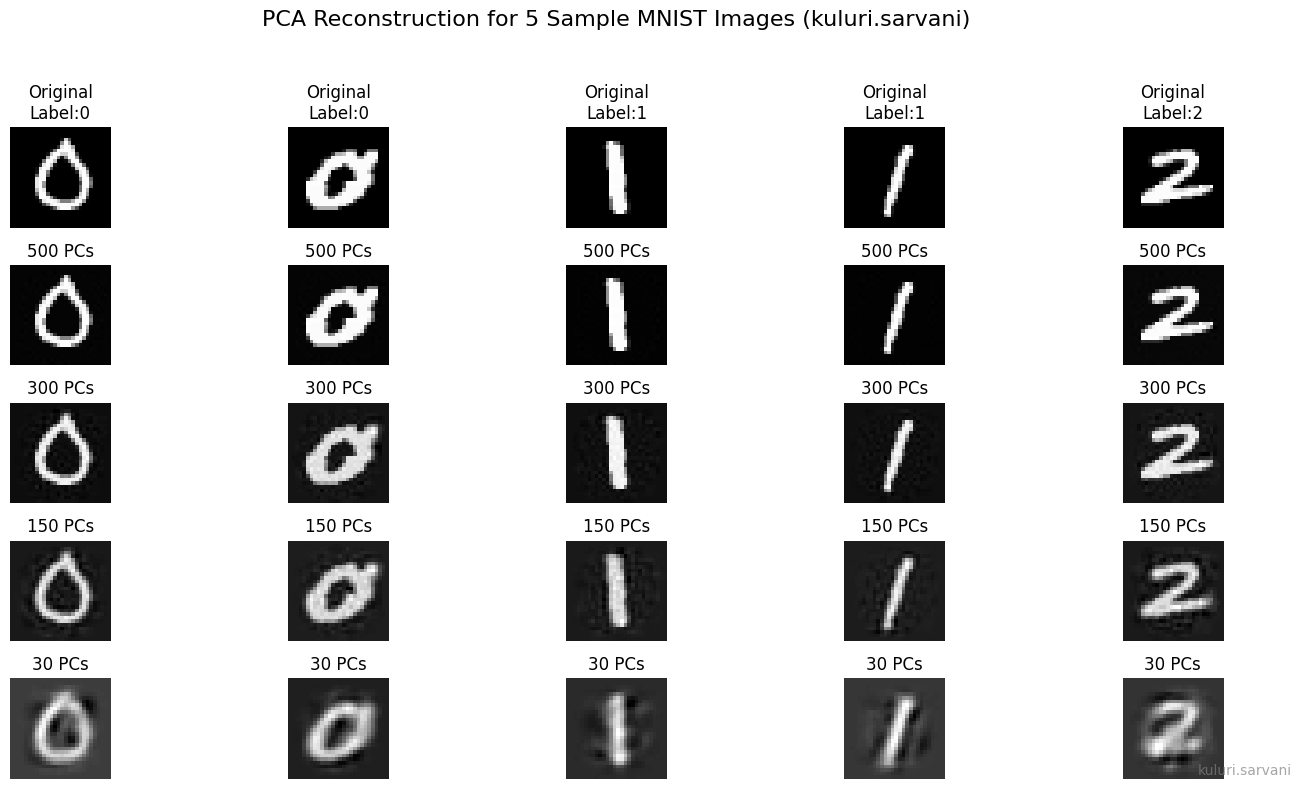

In [18]:
# ===========================================
# 🖼 Reconstruct and visualize 5 sample images
# ===========================================
sample_indices = [0, 50, 100, 150, 200]  # Pick 5 random samples
fig, axes = plt.subplots(len(target_dimensions)+1, len(sample_indices), figsize=(15,8))

for col_idx, idx in enumerate(sample_indices):
    # Original image
    axes[0, col_idx].imshow(X_subset[idx].reshape(28,28), cmap="gray")
    axes[0, col_idx].set_title(f"Original\nLabel:{y_subset[idx]}")
    axes[0, col_idx].axis("off")

# Reconstructed images after PCA projection
for row_idx, n_dim in enumerate(target_dimensions):
    X_trans = pca_results[n_dim]["X_transformed"]
    pca_obj = pca_results[n_dim]["pca"]
    # Reconstruct by projecting back
    X_reconstructed = X_trans.dot(pca_obj.components_.T) + pca_obj.mean_
    
    for col_idx, idx in enumerate(sample_indices):
        axes[row_idx+1, col_idx].imshow(X_reconstructed[idx].reshape(28,28), cmap="gray")
        axes[row_idx+1, col_idx].set_title(f"{n_dim} PCs")
        axes[row_idx+1, col_idx].axis("off")

plt.suptitle(f"PCA Reconstruction for 5 Sample MNIST Images ({username})", fontsize=16)
plt.figtext(0.95, 0.02, username, 
            ha='right', va='bottom', 
            fontsize=10, color='gray', alpha=0.7)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()
